# EDA — Deserción en educación superior (Colombia), IES × año

Análisis exploratorio del dataset que produce `pipeline.py` (`data/processed/dataset_ies.csv`).
Cada fila es una IES en un año (2015–2021); la variable objetivo es `tasa_desercion` (SPADIES, MEN) y las
explicativas llegan rezagadas (Saber 11 y TerriData en t-1; matrícula SNIES en t-2). El contexto territorial se
une por el municipio sede de la IES.

**Alcance.** Se describen asociaciones, no causas, y el nivel de análisis es la institución, no el estudiante.

In [1]:
# Configuración: rutas relativas a la raíz del proyecto y librerías
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.collections import PatchCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Polygon
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.config import load_config
from src.homologation.divipola import cargar_divipola
from src.validate.dictionary import describir_columnas

# Paleta del proyecto: azul = oficial, naranja = privada; rampa azul para magnitudes
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
RAMPA = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#1c5cab", "#0d366b"]
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

## 1. Carga y descripción general

In [2]:
cfg = load_config(ROOT / "config" / "config.yaml")
assert cfg["unidad_analisis"] == "ies", "este EDA es para la unidad IES x año"
ruta = ROOT / cfg["rutas"]["processed"] / "dataset_ies.csv"

# Los códigos son texto para conservar los ceros a la izquierda (p. ej. 05001)
df = pd.read_csv(ruta, dtype={"cod_ies": str, "cod_divipola_mpio": str, "sector": str, "caracter": str})
divipola = cargar_divipola(ROOT / cfg["rutas"]["raw"] / "dane" / "divipola.csv")
deptos = divipola.drop_duplicates("cod_depto").set_index("cod_depto")["depto_norm"].str.title()

df["cod_depto"] = df["cod_divipola_mpio"].str[:2]
df["departamento"] = df["cod_depto"].map(deptos)
df["naturaleza"] = df["sector"].map({"1": "Oficial", "2": "Privada"})  # id_sector de SNIES
assert df["tasa_desercion"].notna().all(), "tasa_desercion tiene nulos: falta el export de SPADIES"

print(f"{len(df):,} filas · {df['cod_ies'].nunique()} IES · años {df['anio'].min()}–{df['anio'].max()} · {df.shape[1]} columnas")
print("IES por naturaleza:", df.drop_duplicates("cod_ies")["naturaleza"].value_counts().to_dict())

2,148 filas · 321 IES · años 2015–2021 · 40 columnas
IES por naturaleza: {'Privada': 226, 'Oficial': 95}


In [3]:
# Control de la codificación de naturaleza contra el catálogo oficial de IES (sector Oficial/Privado)
catalogo = ROOT / cfg["rutas"]["raw"] / "snies" / "ies_catalogo.csv"
if catalogo.exists():
    cat = pd.read_csv(catalogo, dtype=str).rename(columns={"c_digo_instituci_n": "cod_ies", "sector": "sector_catalogo"})
    cruce = df.drop_duplicates("cod_ies").merge(cat[["cod_ies", "sector_catalogo"]], on="cod_ies", how="left")
    display(pd.crosstab(cruce["naturaleza"], cruce["sector_catalogo"].fillna("sin catálogo")))

sector_catalogo,Oficial,Privado,sin catálogo
naturaleza,,,
Oficial,94,0,1
Privada,1,224,1


In [4]:
# Tipos de dato y resumen de las variables numéricas
display(df.dtypes.to_frame("tipo").T)
display(df.describe().T.round(3))

,cod_ies,anio,tasa_desercion,cod_divipola_mpio,sector,caracter,matriculados_ies_t2,punt_global_media_t1,punt_global_mediana_t1,pct_estrato_bajo_t1,pct_colegio_oficial_t1,n_estudiantes_t1,mpio_matriculados_t2,mpio_ies_con_oferta_t2,td_cob_bruta_media_t1,td_cob_bruta_total_t1,td_cob_neta_media_t1,td_desercion_escolar_t1,td_idf_t1,td_idf_ahorro_t1,td_idf_deuda_t1,td_idf_inversion_t1,td_idf_recursos_propios_t1,td_idf_transferencias_t1,td_ipm_censo_t1,td_mdm_t1,td_mdm_educacion_t1,td_mdm_gestion_t1,td_mdm_resultados_t1,td_miseria_pct_t1,td_nbi_pct_t1,td_pct_pob_15_19_t1,td_pct_pob_20_24_t1,td_pct_poblacion_rural_t1,td_repitencia_oficial_t1,td_transito_superior_t1,td_poblacion_total_t1,cod_depto,departamento,naturaleza
tipo,str,int64,float64,str,str,str,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,str,str,str


,count,mean,std,min,25%,50%,75%,max
anio,2148.0,2017.989,1.999,2015.000,2016.000,2018.000,2020.000,2021.000
tasa_desercion,2148.0,0.129,0.106,0.000,0.073,0.100,0.145,0.994
matriculados_ies_t2,1504.0,7902.086,27148.603,6.000,789.750,3310.000,8222.500,467643.000
punt_global_media_t1,1536.0,262.578,13.099,206.894,254.394,264.156,270.213,294.815
punt_global_mediana_t1,1536.0,260.014,14.465,201.000,250.000,263.000,267.000,295.000
pct_estrato_bajo_t1,1536.0,0.635,0.132,0.244,0.552,0.579,0.733,1.000
pct_colegio_oficial_t1,1536.0,0.625,0.124,0.347,0.529,0.614,0.696,1.000
n_estudiantes_t1,1536.0,37264.348,38709.849,74.000,4324.000,17316.000,90956.000,96708.000
mpio_matriculados_t2,2144.0,299789.710,322289.991,54.000,32547.000,126166.000,708245.000,804455.000
mpio_ies_con_oferta_t2,2144.0,57.581,48.048,1.000,16.000,43.000,122.000,126.000


## 2. Distribución de la tasa de deserción

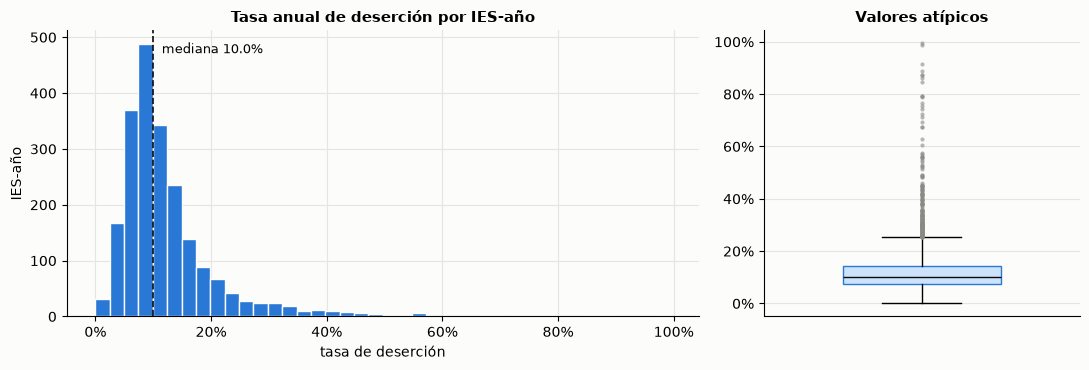

,0.05,0.25,0.50,0.75,0.95
tasa_desercion,0.04,0.073,0.1,0.145,0.311


Asimetría: 3.51 · IES-año con tasa > 50 %: 33


In [5]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [2, 1]})
ejes[0].hist(df["tasa_desercion"], bins=40, color=AZUL, edgecolor="#fcfcfb", linewidth=1)
mediana = df["tasa_desercion"].median()
ejes[0].axvline(mediana, color="#0b0b0b", lw=1.2, ls="--")
ejes[0].annotate(f"mediana {mediana:.1%}", (mediana, ejes[0].get_ylim()[1] * 0.92), xytext=(6, 0),
                 textcoords="offset points", fontsize=9)
ejes[0].set(title="Tasa anual de deserción por IES-año", xlabel="tasa de deserción", ylabel="IES-año")
ejes[0].xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")

ejes[1].boxplot(df["tasa_desercion"], orientation="vertical", widths=0.5, patch_artist=True,
                boxprops=dict(facecolor="#cde2fb", edgecolor=AZUL), medianprops=dict(color="#0b0b0b"),
                flierprops=dict(marker="o", markersize=3, markerfacecolor=GRIS, markeredgecolor="none", alpha=0.6))
ejes[1].set(title="Valores atípicos", xticks=[])
ejes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()
plt.show()

q = df["tasa_desercion"].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(3)
display(q.to_frame("tasa_desercion").T)
print(f"Asimetría: {stats.skew(df['tasa_desercion']):.2f} · IES-año con tasa > 50 %: {(df['tasa_desercion'] > 0.5).sum()}")

In [6]:
# Las tasas muy altas suelen venir de IES pequeñas o de crecimiento rápido (el denominador es la matrícula de hace un año)
altas = df[df["tasa_desercion"] > 0.5].copy()
display(altas[["cod_ies", "anio", "departamento", "naturaleza", "tasa_desercion", "matriculados_ies_t2"]]
        .sort_values("tasa_desercion", ascending=False).head(10).round(3))
print("Matrícula t-2 mediana de las IES-año con tasa > 50 %:", altas["matriculados_ies_t2"].median(),
      "· del resto:", df.loc[df["tasa_desercion"] <= 0.5, "matriculados_ies_t2"].median())

,cod_ies,anio,departamento,naturaleza,tasa_desercion,matriculados_ies_t2
2083,9903,2019,"Bogota, D.C.",Privada,0.994,146.0
2084,9903,2020,"Bogota, D.C.",Privada,0.987,184.0
1841,4812,2020,"Bogota, D.C.",Privada,0.917,376.0
1375,3114,2018,Atlantico,Oficial,0.889,130.0
2080,9903,2016,"Bogota, D.C.",Privada,0.873,NaN
793,2106,2016,"Bogota, D.C.",Oficial,0.873,NaN
1758,4710,2017,"Bogota, D.C.",Privada,0.861,NaN
1821,4808,2019,Valle Del Cauca,Privada,0.846,63.0
2085,9903,2021,"Bogota, D.C.",Privada,0.794,177.0
2082,9903,2018,"Bogota, D.C.",Privada,0.792,278.0


Matrícula t-2 mediana de las IES-año con tasa > 50 %: 254.0 · del resto: 3348.0


## 3. Evolución 2015–2021

,mediana,media,p25,p75,n
anio,,,,,
2015,0.107,0.139,0.077,0.161,308
2016,0.101,0.134,0.077,0.150,310
2017,0.112,0.139,0.080,0.157,307
2018,0.099,0.125,0.074,0.142,307
2019,0.097,0.119,0.071,0.138,308
2020,0.095,0.125,0.070,0.136,304
2021,0.091,0.123,0.063,0.142,304


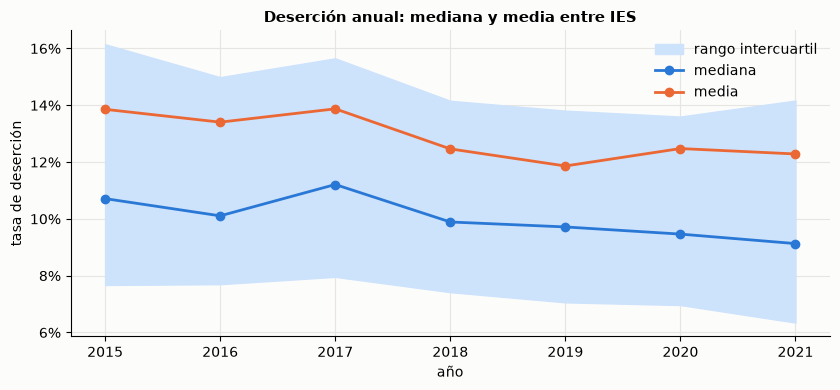

In [7]:
por_anio = df.groupby("anio")["tasa_desercion"].agg(
    mediana="median", media="mean", p25=lambda s: s.quantile(0.25), p75=lambda s: s.quantile(0.75), n="size")
display(por_anio.round(3))

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.fill_between(por_anio.index, por_anio["p25"], por_anio["p75"], color="#cde2fb", label="rango intercuartil")
ax.plot(por_anio.index, por_anio["mediana"], color=AZUL, lw=2, marker="o", markersize=6, label="mediana")
ax.plot(por_anio.index, por_anio["media"], color=NARANJA, lw=2, marker="o", markersize=6, label="media")
ax.set(title="Deserción anual: mediana y media entre IES", xlabel="año", ylabel="tasa de deserción")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
plt.show()

## 4. Oficial frente a privada

,size,median,mean,std
naturaleza,,,,
Oficial,637,0.085,0.108,0.086
Privada,1511,0.106,0.138,0.112


Mann-Whitney U (oficial vs. privada): p = 2.96e-17. Las observaciones de una misma IES no son independientes, así que el valor p es solo orientativo.


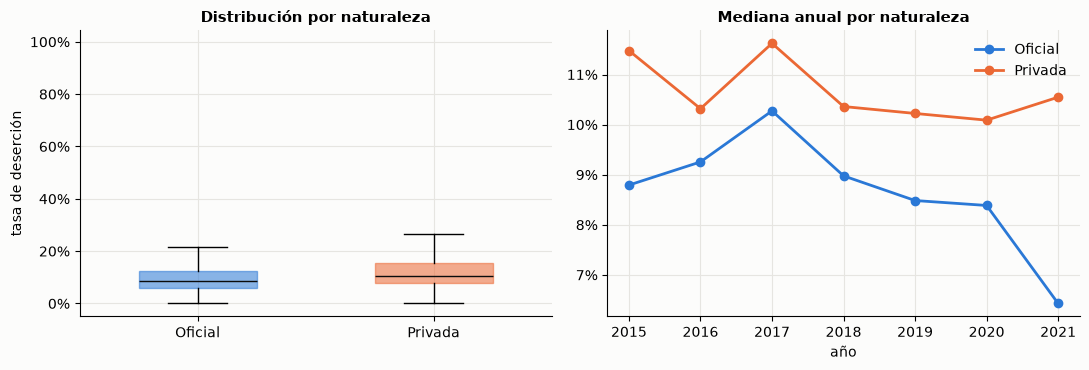

In [8]:
resumen = df.groupby("naturaleza")["tasa_desercion"].agg(["size", "median", "mean", "std"]).round(3)
display(resumen)
oficial = df.loc[df["naturaleza"] == "Oficial", "tasa_desercion"]
privada = df.loc[df["naturaleza"] == "Privada", "tasa_desercion"]
u, p = stats.mannwhitneyu(oficial, privada)
print(f"Mann-Whitney U (oficial vs. privada): p = {p:.3g}. Las observaciones de una misma IES no son independientes, "
      "así que el valor p es solo orientativo.")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
ejes[0].boxplot([oficial, privada], tick_labels=["Oficial", "Privada"], widths=0.5, patch_artist=True,
                medianprops=dict(color="#0b0b0b"),
                flierprops=dict(marker="o", markersize=3, markeredgecolor="none", alpha=0.5))
for caja, color in zip(ejes[0].patches, [AZUL, NARANJA]):
    caja.set(facecolor=color, alpha=0.55, edgecolor=color)
ejes[0].set(title="Distribución por naturaleza", ylabel="tasa de deserción")
ejes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")

serie = df.groupby(["anio", "naturaleza"])["tasa_desercion"].median().unstack()
for nombre, color in (("Oficial", AZUL), ("Privada", NARANJA)):
    ejes[1].plot(serie.index, serie[nombre], color=color, lw=2, marker="o", markersize=6, label=nombre)
ejes[1].set(title="Mediana anual por naturaleza", xlabel="año")
ejes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ejes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

## 5. Por departamento (sede de la IES)

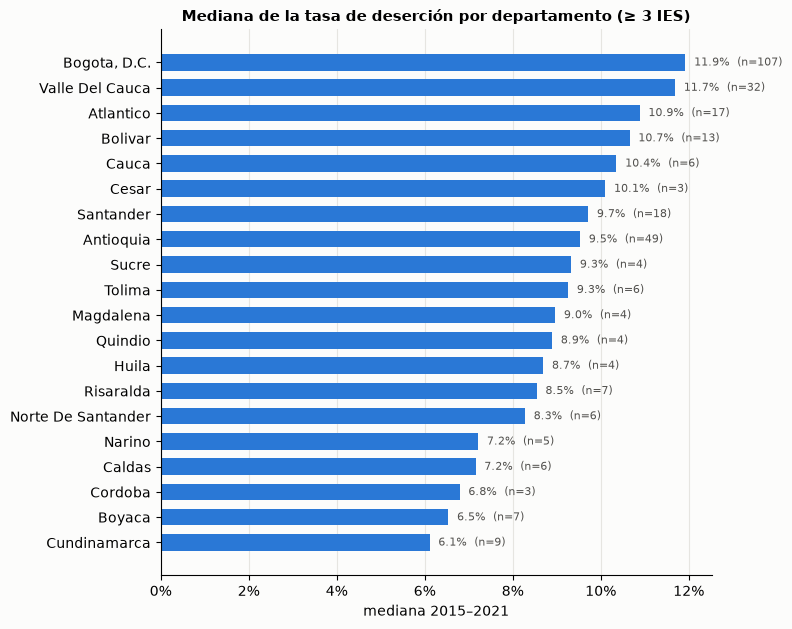

27 departamentos con IES en el dataset; 7 tienen menos de 3 y no se grafican.


In [9]:
dep = df.groupby("departamento").agg(ies=("cod_ies", "nunique"), mediana=("tasa_desercion", "median"),
                                       media=("tasa_desercion", "mean")).sort_values("mediana")
# Con pocas IES la mediana departamental es muy inestable: se grafican solo los departamentos con 3 o más
grande = dep[dep["ies"] >= 3]
fig, ax = plt.subplots(figsize=(8, max(3, 0.32 * len(grande))))
ax.barh(grande.index, grande["mediana"], color=AZUL, height=0.65)
for y, (m, n) in enumerate(zip(grande["mediana"], grande["ies"])):
    ax.text(m + 0.002, y, f"{m:.1%}  (n={n})", va="center", fontsize=8, color="#52514e")
ax.set(title="Mediana de la tasa de deserción por departamento (≥ 3 IES)", xlabel="mediana 2015–2021")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(f"{len(dep)} departamentos con IES en el dataset; {len(dep) - len(grande)} tienen menos de 3 y no se grafican.")

## 6. Valores nulos por fuente

,% nulos promedio,% nulos máximo,variables
fuente,,,
Saber 11 (ICFES),28.5,28.5,5
SNIES (MEN),6.1,30.0,5
TerriData (DNP),6.1,29.0,23


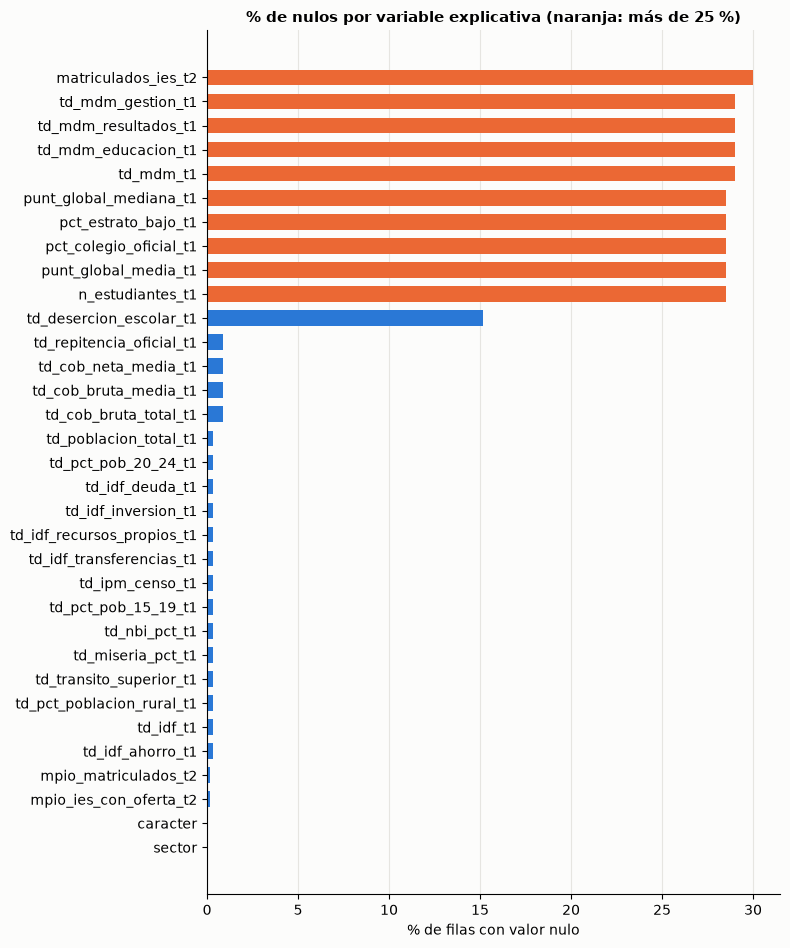

In [10]:
fuentes, _ = describir_columnas(list(df.columns))
explicativas = [c for c in df.columns if c in fuentes and c not in ("tasa_desercion", "cod_ies", "cod_divipola_mpio", "anio")]
nulos = (df[explicativas].isna().mean() * 100).rename("% nulos").to_frame()
nulos["fuente"] = [fuentes[c] for c in nulos.index]

por_fuente = nulos.groupby("fuente")["% nulos"].agg(["mean", "max", "size"]).round(1)
por_fuente.columns = ["% nulos promedio", "% nulos máximo", "variables"]
display(por_fuente.sort_values("% nulos promedio", ascending=False))

fig, ax = plt.subplots(figsize=(8, 0.26 * len(nulos) + 1))
orden = nulos.sort_values("% nulos")
ax.barh(orden.index, orden["% nulos"], color=[NARANJA if v > 25 else AZUL for v in orden["% nulos"]], height=0.65)
ax.set(title="% de nulos por variable explicativa (naranja: más de 25 %)", xlabel="% de filas con valor nulo")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [11]:
# Variables descartadas por exceso de nulos y otras observaciones de calidad de la última corrida
log = (ROOT / cfg["rutas"]["reports"] / "etl_log.md").read_text(encoding="utf-8")
for linea in log.splitlines():
    if "descartada(s) por superar" in linea or "sin municipio sede" in linea or "cobertura incompleta" in linea:
        print(linea[:400])

- Saber 11: cobertura incompleta en los años [2018, 2020, 2021] (falta el calendario A); se excluyen, por lo que las variables Saber 11 de los años [2019, 2021, 2022] quedan nulas
- TerriData: 5 de 28 variable(s) descartada(s) por superar 50% de nulos tras el rezago: td_cob_superior_t1 (57%), td_cotizantes_t1 (57%), td_empresas_empleo_formal_t1 (57%), td_ocupacion_formal_pct_t1 (57%), td_tgp_t1 (65%)
- TerriData: 1 de 321 IES sin municipio sede en TerriData (4106→88001); quedan con sus variables td_* nulas


**Lectura.** Los nulos de `matriculados_ies_t2` en 2015–2016 son esperados (la matrícula por programa de SNIES empieza en 2015
y el rezago es de dos años). Las de Saber 11 vienen de los años con cobertura incompleta del calendario A, que el ETL excluye
en vez de usar una muestra sesgada.

## 7. Correlaciones de las variables explicativas con la tasa

,matriculados_ies_t2,td_pct_poblacion_rural_t1,td_cob_bruta_total_t1,td_idf_transferencias_t1,pct_colegio_oficial_t1,td_idf_deuda_t1,td_cob_bruta_media_t1,td_idf_inversion_t1,td_mdm_educacion_t1,td_pct_pob_15_19_t1,td_desercion_escolar_t1,td_repitencia_oficial_t1,pct_estrato_bajo_t1,td_mdm_resultados_t1,td_nbi_pct_t1,td_idf_recursos_propios_t1,td_transito_superior_t1,td_miseria_pct_t1,td_ipm_censo_t1,td_cob_neta_media_t1,punt_global_mediana_t1,punt_global_media_t1,td_mdm_t1,td_idf_ahorro_t1,td_mdm_gestion_t1,td_pct_pob_20_24_t1,td_idf_t1,mpio_matriculados_t2,n_estudiantes_t1,mpio_ies_con_oferta_t2,td_poblacion_total_t1,privada
rho de Spearman,-0.356,-0.175,-0.16,-0.141,-0.132,-0.127,-0.127,-0.117,-0.089,-0.08,-0.068,-0.056,-0.049,-0.023,-0.01,-0.007,-0.002,0.001,0.008,0.016,0.025,0.034,0.09,0.093,0.095,0.108,0.123,0.124,0.137,0.145,0.154,0.182


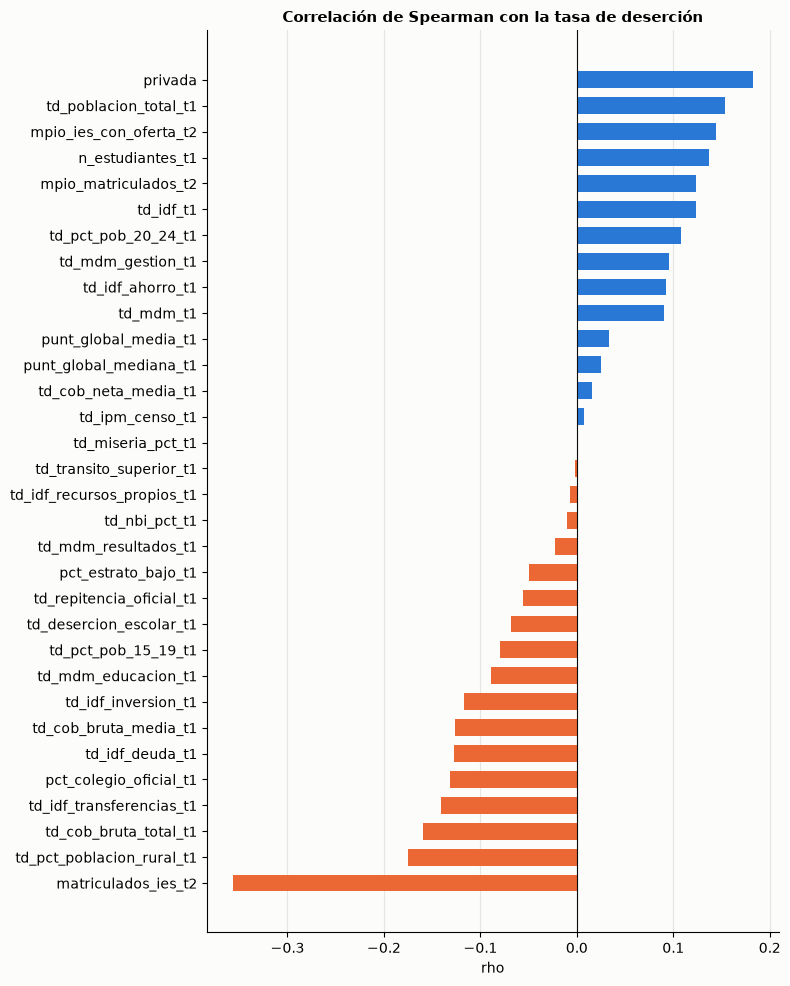

In [12]:
excluir = {"tasa_desercion", "anio"}
numericas = [c for c in df.select_dtypes("number").columns if c not in excluir]
X = df[numericas].copy()
X["privada"] = (df["naturaleza"] == "Privada").astype(int)

# Spearman: resistente a los valores atípicos de la tasa y a las relaciones no lineales monótonas
corr = X.corrwith(df["tasa_desercion"], method="spearman").dropna().sort_values()
display(corr.round(3).to_frame("rho de Spearman").T)

fig, ax = plt.subplots(figsize=(8, 0.28 * len(corr) + 1))
ax.barh(corr.index, corr.values, color=[AZUL if v >= 0 else NARANJA for v in corr.values], height=0.65)
ax.axvline(0, color="#0b0b0b", lw=0.8)
ax.set(title="Correlación de Spearman con la tasa de deserción", xlabel="rho")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

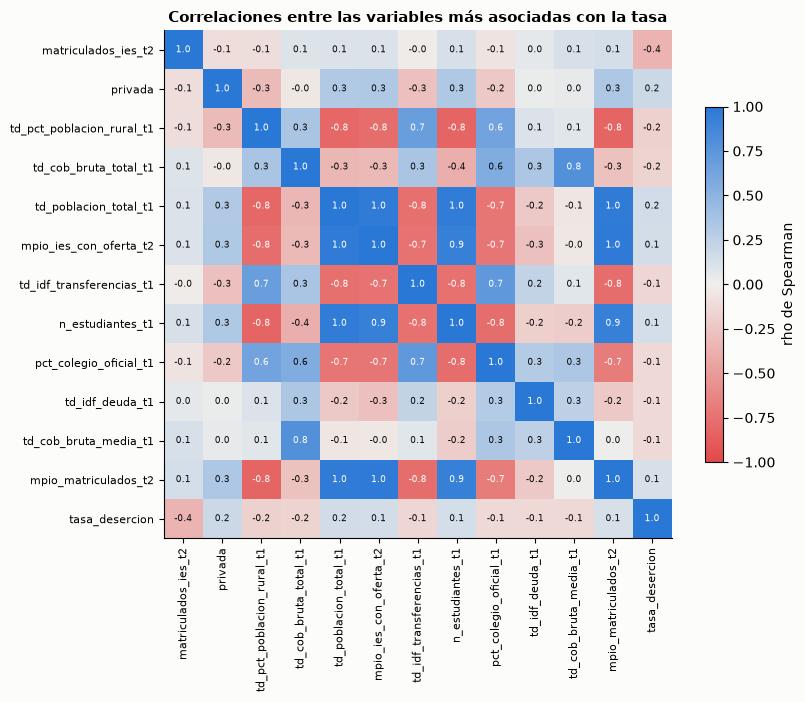

In [13]:
# Las 12 variables más asociadas con la tasa y su correlación entre sí (para detectar redundancia)
top = corr.abs().sort_values(ascending=False).head(12).index.tolist()
mat = X[top + ["privada"] if "privada" not in top else top].assign(tasa_desercion=df["tasa_desercion"]).corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
mapa = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
im = ax.imshow(mat.values, cmap=mapa, vmin=-1, vmax=1)
ax.set_xticks(range(len(mat)), mat.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(mat)), mat.index, fontsize=8)
for i in range(len(mat)):
    for j in range(len(mat)):
        ax.text(j, i, f"{mat.values[i, j]:.1f}", ha="center", va="center", fontsize=6.5,
                color="#0b0b0b" if abs(mat.values[i, j]) < 0.6 else "#ffffff")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.7, label="rho de Spearman")
ax.set_title("Correlaciones entre las variables más asociadas con la tasa")
plt.tight_layout()
plt.show()

**Precauciones.** `matriculados_ies_t2` casi coincide con el denominador de la tasa, de modo que su asociación es en parte
mecánica. Varias variables territoriales (TerriData) son muy parecidas entre sí; antes de modelar conviene
reducirlas o regularizarlas. Las IES con sede en una misma ciudad comparten todo su contexto territorial.

## 8. Mapa por departamento

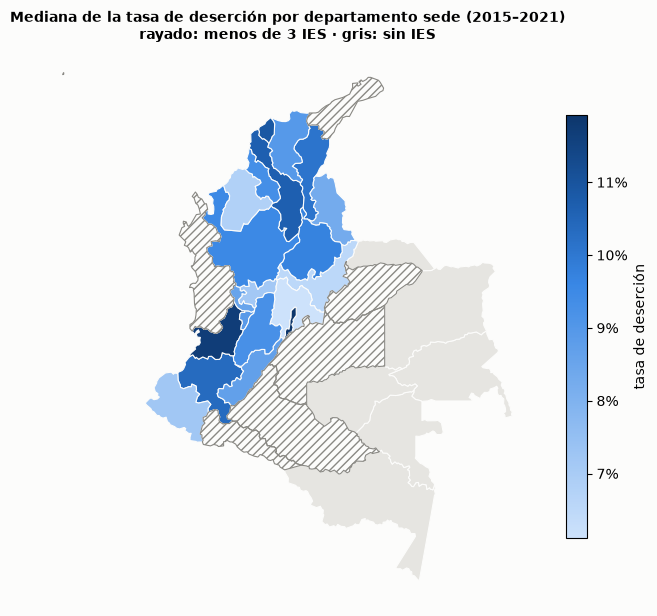

,departamento,mediana,IES
0,"Archipielago De San Andres, Providencia Y Sant...",0.353,1
1,La Guajira,0.228,2
2,"Bogota, D.C.",0.119,107
3,Valle Del Cauca,0.117,32
4,Putumayo,0.116,2
5,Casanare,0.115,1
6,Atlantico,0.109,17
7,Bolivar,0.107,13
8,Cauca,0.104,6
9,Cesar,0.101,3


Rayado: departamentos con 1 o 2 IES (la mediana describe solo a esas instituciones); gris: sin IES en el dataset.


In [14]:
# Polígonos departamentales del DANE (MGN 2018), guardados en data/external; se dibujan con matplotlib sin geopandas
geo = json.loads((ROOT / "data" / "external" / "departamentos_colombia.geojson").read_text(encoding="utf-8"))
valor_todos = df.groupby("cod_depto")["tasa_desercion"].median()
n_ies = df.groupby("cod_depto")["cod_ies"].nunique()
# Con 1 o 2 IES la mediana departamental no es representativa: se pintan aparte y no fijan la escala de color
valor = valor_todos[n_ies.reindex(valor_todos.index) >= 3]

norma = Normalize(vmin=valor.min(), vmax=valor.max())
cmap = LinearSegmentedColormap.from_list("rampa", RAMPA)
parches, colores, pocas = [], [], []
for f in geo["features"]:
    cod = f["properties"]["DPTO_CCDGO"]
    anillo = np.array(f["geometry"]["coordinates"][0])
    parches.append(Polygon(anillo, closed=True))
    if cod in valor.index:
        colores.append(cmap(norma(valor[cod])))
    else:
        colores.append("#fcfcfb" if cod in valor_todos.index else "#e6e5e1")
    pocas.append(cod in valor_todos.index and cod not in valor.index)

fig, ax = plt.subplots(figsize=(6.5, 8))
ax.add_collection(PatchCollection(parches, facecolor=colores, edgecolor="#fcfcfb", linewidth=0.8))
# trama diagonal sobre los departamentos con menos de 3 IES
ax.add_collection(PatchCollection([p for p, m in zip(parches, pocas) if m], facecolor="none", edgecolor=GRIS,
                                  hatch="////", linewidth=0.8))
ax.autoscale_view()
ax.set_aspect("equal")
ax.set_axis_off()
ax.set_title("Mediana de la tasa de deserción por departamento sede (2015–2021)\nrayado: menos de 3 IES · gris: sin IES", fontsize=10)
barra = fig.colorbar(plt.cm.ScalarMappable(norm=norma, cmap=cmap), ax=ax, shrink=0.55, label="tasa de deserción")
barra.ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()
plt.show()

mapa_tabla = pd.DataFrame({"departamento": valor_todos.index.map(deptos), "mediana": valor_todos.values,
                           "IES": n_ies.reindex(valor_todos.index).values})
display(mapa_tabla.sort_values("mediana", ascending=False).round(3).reset_index(drop=True))
print("Rayado: departamentos con 1 o 2 IES (la mediana describe solo a esas instituciones); gris: sin IES en el dataset.")

## Conclusiones

- **Distribución.** La tasa anual de deserción por IES tiene mediana 10,0 %, media 12,9 % y un rango entre el percentil 5 y el 95 de 4,0 % a 31,1 %. Es muy asimétrica (3,5): hay 33 IES-año por encima de 50 %, casi todas de instituciones pequeñas (matrícula t-2 mediana de 254 frente a 3.348 en el resto), porque el denominador es chico. Antes de modelar hay que decidir si se winsoriza o se filtra por tamaño.
- **Evolución.** La mediana baja de 10,7 % en 2015 a 9,1 % en 2021 y la media de 13,9 % a 12,3 %, con un máximo en 2017 (11,2 % de mediana). No se ve un salto en 2020; con siete años y un denominador rezagado no conviene leerlo como efecto de la pandemia.
- **Oficial y privada.** Las privadas (226 IES) tienen mediana 10,6 % y media 13,8 %; las oficiales (95 IES), 8,5 % y 10,8 %. La diferencia es consistente en el tiempo (gráfico de líneas), pero las filas de una misma IES no son independientes, así que el valor p de Mann-Whitney solo es orientativo.
- **Departamentos.** Entre los 20 departamentos con 3 o más IES, Bogotá (11,9 %), Valle del Cauca (11,7 %), Atlántico (10,9 %) y Bolívar (10,7 %) tienen las medianas más altas; Cundinamarca (6,1 %), Boyacá (6,5 %) y Córdoba (6,8 %), las más bajas. Esas diferencias mezclan efecto territorial con composición (peso de privadas, tamaño de las IES), y 7 departamentos con 1 o 2 IES describen solo a esas instituciones (el mapa las marca aparte).
- **Nulos.** Saber 11 tiene 28,5 % de nulos (años excluidos por cobertura incompleta del calendario A), la matrícula de SNIES hasta 30 % (`matriculados_ies_t2` en 2015–2016) y TerriData 6,1 % en promedio (máximo 29 % en el desempeño municipal, que empieza en 2016). Se descartaron 5 variables de TerriData por más de 50 % de nulos: cobertura en educación superior y todo el bloque de mercado laboral (cotizantes, empresas, ocupación formal, participación), cuyas series o terminan en 2016 o empiezan en 2018.
- **Correlaciones.** Ninguna variable explica mucho por sí sola (|rho| ≤ 0,36). La más fuerte es negativa: `matriculados_ies_t2` (-0,36); IES más grandes, menor tasa, en parte por construcción, porque es casi el denominador. Le siguen el porcentaje de población rural (-0,18), la cobertura bruta (-0,16) y la dependencia de transferencias (-0,14), y, con signo positivo, ser privada (+0,18), la población (+0,15) y el número de IES del municipio (+0,15). Las variables territoriales son muy colineales entre sí (población, matrícula municipal y estudiantes de Saber 11 con rho cercana a 1), de modo que habrá que reducirlas o regularizarlas.
- **Pendientes para el modelo.** Tratamiento de las tasas atípicas, colinealidad territorial, el solapamiento entre `matriculados_ies_t2` y el denominador, y validación por IES (no por filas) para no inflar el desempeño con observaciones repetidas de la misma institución.